In [5]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets,transforms
import matplotlib.pyplot as plt
import numpy as np

torch.manual_seed(42)

device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [6]:
IMAGE_SIZE=32
PATCH_SIZE=4
CHANNELS=3
EMBED_DIM=124
NUM_HEADS=4
NUM_LAYERS=4
MLP_DIM=256
NUM_CLASSES=10
BATCH_SIZE=128
EPOCHS=10
LEARNING_RATE=3e-4

NUM_PATCHES=(IMAGE_SIZE//PATCH_SIZE) **2
PATCH_DIM=CHANNELS* PATCH_SIZE * PATCH_SIZE

In [7]:
print("Number of patches:",NUM_PATCHES)
print("Values in each flattened patch:",PATCH_DIM)
print("Embedding dimension:", EMBED_DIM)

Number of patches: 64
Values in each flattened patch: 48
Embedding dimension: 124


In [8]:
transform=transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.5,0.5,0.5),
        std=(0.5,0.5,0.5)
    )
])

In [9]:
train_dataset=datasets.CIFAR10(root="./datasets",train=True,download=True,transform=transform)
test_dataset=datasets.CIFAR10(root="./datasets",train=False,download=True,transform=transform)

100%|██████████| 170M/170M [23:18<00:00, 122kB/s]


In [10]:
train_loader=DataLoader(train_dataset,batch_size=BATCH_SIZE,shuffle=True,num_workers=2)
test_loader=DataLoader(test_dataset,batch_size=BATCH_SIZE,shuffle=False,num_workers=2)
class_names=train_dataset.classes
print(class_names)

['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [11]:
print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))

Training images: 50000
Testing images: 10000


In [12]:
sample_images,_=next(iter(train_loader))
sample=sample_images[:2]
sample

tensor([[[[-0.1529, -0.1373, -0.2392,  ..., -0.1529, -0.3098, -0.3961],
          [-0.7255, -0.4275, -0.3098,  ..., -0.3176, -0.1922, -0.2627],
          [-0.7176, -0.9294, -0.7255,  ..., -0.5451, -0.3020, -0.3176],
          ...,
          [-0.1765, -0.2471, -0.3098,  ..., -0.1373, -0.0824, -0.1843],
          [-0.0824, -0.3882, -0.2941,  ..., -0.0902, -0.0275, -0.1765],
          [-0.0980, -0.1686, -0.0353,  ..., -0.0745, -0.4353, -0.3882]],

         [[ 0.3176,  0.3961,  0.3333,  ...,  0.1059, -0.0353, -0.0980],
          [-0.2784,  0.0588,  0.1922,  ..., -0.0275,  0.0980,  0.0353],
          [-0.2392, -0.4588, -0.3020,  ..., -0.2235,  0.0118, -0.0196],
          ...,
          [ 0.5137,  0.4353,  0.3725,  ...,  0.3412,  0.3804,  0.2627],
          [ 0.5216,  0.1922,  0.2706,  ...,  0.3725,  0.4196,  0.2549],
          [ 0.4902,  0.4275,  0.5686,  ...,  0.3725, -0.0588,  0.0353]],

         [[-0.4510, -0.4275, -0.5373,  ..., -0.4745, -0.6471, -0.7412],
          [-0.8118, -0.6078, -

In [19]:
patches = sample.unfold(2, PATCH_SIZE, PATCH_SIZE)
print(patches.shape)

torch.Size([2, 3, 8, 32, 4])


In [20]:
patches = patches.unfold(3, PATCH_SIZE, PATCH_SIZE)
print("After unfold:", patches.shape)

After unfold: torch.Size([2, 3, 8, 8, 4, 4])


In [21]:
patches = patches.permute(0, 2, 3, 1, 4, 5)
patches = patches.reshape(sample.shape[0], NUM_PATCHES, PATCH_DIM)
print("Flattened patches:",patches.shape)

Flattened patches: torch.Size([2, 64, 48])


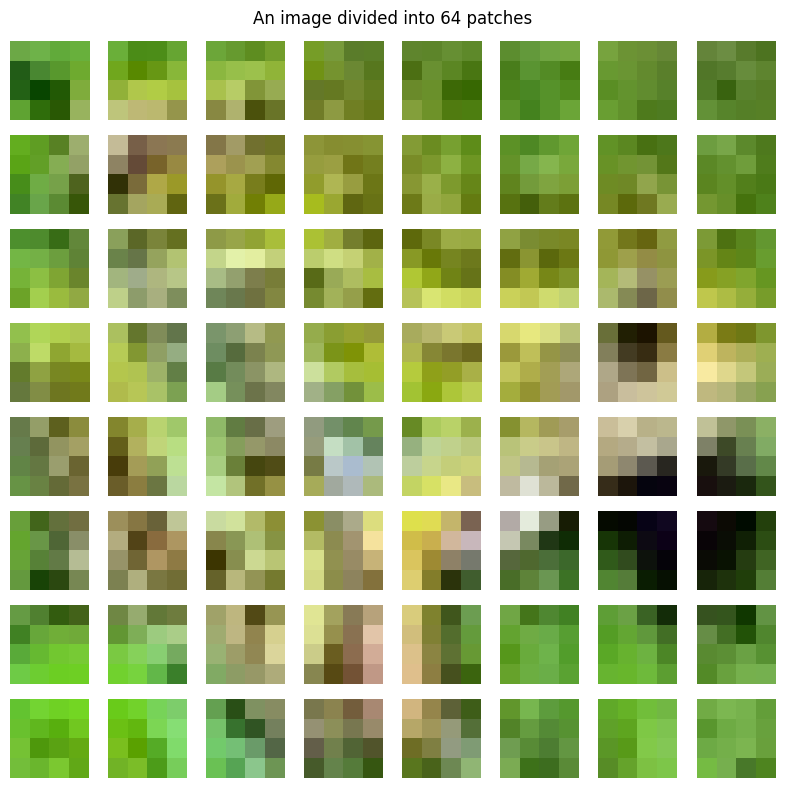

In [23]:
image=sample_images[0] * 0.5+0.5
fig,axes=plt.subplots(8,8,figsize=(8,8))

for idx,ax in enumerate(axes.flat):
    row=idx // 8
    col=idx % 8

    patch=image[:,row*PATCH_SIZE:(row+1) *PATCH_SIZE,col *PATCH_SIZE:(col+1)*PATCH_SIZE]
    ax.imshow(patch.permute(1,2,0).numpy())
    ax.axis("off")

plt.suptitle("An image divided into 64 patches")
plt.tight_layout()
plt.show()

In [26]:
class PatchEmbedding(nn.Module):
    def __init__(self,patch_dim,embed_dim):
        super().__init__()
        self.projecttion=nn.Linear(patch_dim,embed_dim)

    def forward(self,x):
        B,C,H,W=x.shape
        x=x.unfold(2,PATCH_SIZE,PATCH_SIZE)
        x=x.unfold(3,PATCH_SIZE,PATCH_SIZE)
        x=x.permute(0,2,3,1,4,5)
        x=x.reshape(B,NUM_PATCHES,-1)
        x=self.projecttion(x)
        return x

In [27]:
patch_embed=PatchEmbedding(PATCH_DIM,EMBED_DIM)
embedded=patch_embed(sample_images[:2])
print("Patch embedding shape:", embedded.shape)

Patch embedding shape: torch.Size([2, 64, 124])


In [28]:
class_token=nn.Parameter(torch.zeros(1,1,EMBED_DIM))

In [29]:
B=embedded.shape[0]
cls_tokens=class_token.expand(B,-1,-1)

In [30]:
tokens=torch.cat((cls_tokens,embedded),dim=1)
print("After adding class token:",tokens.shape)

After adding class token: torch.Size([2, 65, 124])


In [33]:
pos_embedding = nn.Parameter(torch.zeros(1, NUM_PATCHES + 1, EMBED_DIM))
tokens = tokens + pos_embedding
print("After positional embedding:", tokens.shape)

After positional embedding: torch.Size([2, 65, 124])


In [35]:
class SelfAttention(nn.Module):
    def __init__(self, embed_dim):
        super().__init__()
        self.query=nn.Linear(embed_dim,embed_dim)
        self.key=nn.Linear(embed_dim,embed_dim)
        self.value=nn.Linear(embed_dim,embed_dim)

    def forward(self,x):
        Q=self.query(x)
        K=self.key(x)
        V=self.value(x)

        d_k=Q.shape[-1]

        scores=torch.matmul(Q,K.transpose(-2,-1))
        scores=scores/(d_k ** 0.5)

        attention_weights=torch.softmax(scores,dim=-1)
        output=torch.matmul(attention_weights,V)

        return output,attention_weights

attention=SelfAttention(EMBED_DIM)
attn_output,attn_weights=attention(tokens)

print("Attention output:", attn_output.shape)
print("Attention weightsL:", attn_weights.shape)

Attention output: torch.Size([2, 65, 124])
Attention weightsL: torch.Size([2, 65, 65])


In [46]:
class MultiHeadAttention(nn.Module):
    def __init__(self,embed_dim,num_heads):
        super().__init__()
        assert embed_dim % num_heads==0

        self.num_heads=num_heads
        self.head_dim=embed_dim // num_heads

        self.qkv = nn.Linear(embed_dim, embed_dim * 3)
        self.projection=nn.Linear(embed_dim,embed_dim)

    def forward(self,x):
        B,N,D=x.shape
        qkv=self.qkv(x)
        qkv=qkv.reshape(B,N,3,self.num_heads,self.head_dim)
        qkv=qkv.permute(2,0,3,1,4)
        Q,K,V=qkv[0],qkv[1],qkv[2]

        scores=Q @ K.transpose(-2,-1,)
        scores=scores/(self.head_dim **0.5)
        attention=torch.softmax(scores,dim=-1)

        output=attention @V
        output=output.transpose(1,2).contiguous()
        output=output.reshape(B,N,D)
        output=self.projection(output)

        return output,attention

In [47]:
mha=MultiHeadAttention(EMBED_DIM,NUM_HEADS)
mha_output,mha_weights=mha(tokens)

print("MHA output:", mha_output.shape)
print("MHA attention weights:",mha_weights.shape)

MHA output: torch.Size([2, 65, 124])
MHA attention weights: torch.Size([2, 4, 65, 65])


In [48]:
class MLP(nn.Module):
    def __init__(self,embed_dim,mlp_dim):
        super().__init__()
        self.layers=nn.Sequential(
            nn.Linear(embed_dim,mlp_dim),
            nn.GELU(),
            nn.Linear(mlp_dim,embed_dim)
        )

    def forward(self,x):
        return self.layers(x)

In [49]:
mlp=MLP(EMBED_DIM,MLP_DIM)
mlp_outpput=mlp(mha_output)

print("MLP output:", mlp_outpput.shape)

MLP output: torch.Size([2, 65, 124])


In [ ]:
class TransformerEncoderBlock(nn.Module):
    def __init__(self):
        super().__init__()